In [1]:
import geopandas as gpd

In [2]:
states = gpd.read_file("India.shp")

In [3]:
states

,State_Name,geometry
0,Andaman & Nicobar,"MULTIPOLYGON (((10341718.474 1449533.161, 1034..."
1,Chandigarh,"POLYGON ((8546255.616 3606050.813, 8546315.4 3..."
2,Daman and Diu and Dadra and Nagar Haveli,"MULTIPOLYGON (((8122247.822 2312434.407, 81223..."
3,Delhi,"POLYGON ((8583390.57 3359116.19, 8583476.212 3..."
4,Haryana,"POLYGON ((8524318.539 3516490.865, 8524451.392..."
5,Jharkhand,"POLYGON ((9762288.285 2772949.712, 9762301.816..."
6,Karnataka,"MULTIPOLYGON (((8608594.474 2090389.205, 86086..."
7,Kerala,"POLYGON ((8347733.191 1436381.747, 8347795.744..."
8,Lakshadweep,"MULTIPOLYGON (((8135256.29 930182.487, 8135260..."
9,Madhya Pradesh,"POLYGON ((8724343.278 3106498.184, 8724579.382..."


In [4]:
states.head()

,State_Name,geometry
0,Andaman & Nicobar,"MULTIPOLYGON (((10341718.474 1449533.161, 1034..."
1,Chandigarh,"POLYGON ((8546255.616 3606050.813, 8546315.4 3..."
2,Daman and Diu and Dadra and Nagar Haveli,"MULTIPOLYGON (((8122247.822 2312434.407, 81223..."
3,Delhi,"POLYGON ((8583390.57 3359116.19, 8583476.212 3..."
4,Haryana,"POLYGON ((8524318.539 3516490.865, 8524451.392..."


In [5]:
states.columns

Index(['State_Name', 'geometry'], dtype='str')

In [6]:
states.geometry

0     MULTIPOLYGON (((10341718.474 1449533.161, 1034...
1     POLYGON ((8546255.616 3606050.813, 8546315.4 3...
2     MULTIPOLYGON (((8122247.822 2312434.407, 81223...
3     POLYGON ((8583390.57 3359116.19, 8583476.212 3...
4     POLYGON ((8524318.539 3516490.865, 8524451.392...
5     POLYGON ((9762288.285 2772949.712, 9762301.816...
6     MULTIPOLYGON (((8608594.474 2090389.205, 86086...
7     POLYGON ((8347733.191 1436381.747, 8347795.744...
8     MULTIPOLYGON (((8135256.29 930182.487, 8135260...
9     POLYGON ((8724343.278 3106498.184, 8724579.382...
10    MULTIPOLYGON (((8280974.863 2515416.345, 82809...
11    MULTIPOLYGON (((9578537.936 2579790.782, 95786...
12    MULTIPOLYGON (((8878474.16 1232399.36, 8878488...
13    MULTIPOLYGON (((8939353.702 1513831.235, 89395...
14    POLYGON ((9275926.808 2765881.317, 9276185.437...
15    POLYGON ((8720284.876 2259244.214, 8720421.528...
16    POLYGON ((9426056.496 2174632.352, 9426228.484...
17    POLYGON ((9150619.186 1888315.624, 9149005

In [7]:
states.crs

<Projected CRS: EPSG:3857>
Name: WGS 84 / Pseudo-Mercator
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: World between 85.06°S and 85.06°N.
- bounds: (-180.0, -85.06, 180.0, 85.06)
Coordinate Operation:
- name: Popular Visualisation Pseudo-Mercator
- method: Popular Visualisation Pseudo Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

<Axes: >

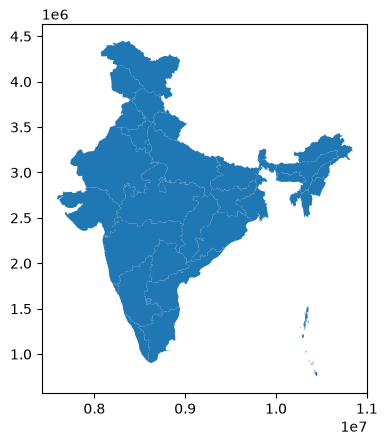

In [8]:
states.plot()

In [9]:
import matplotlib.pyplot as plt

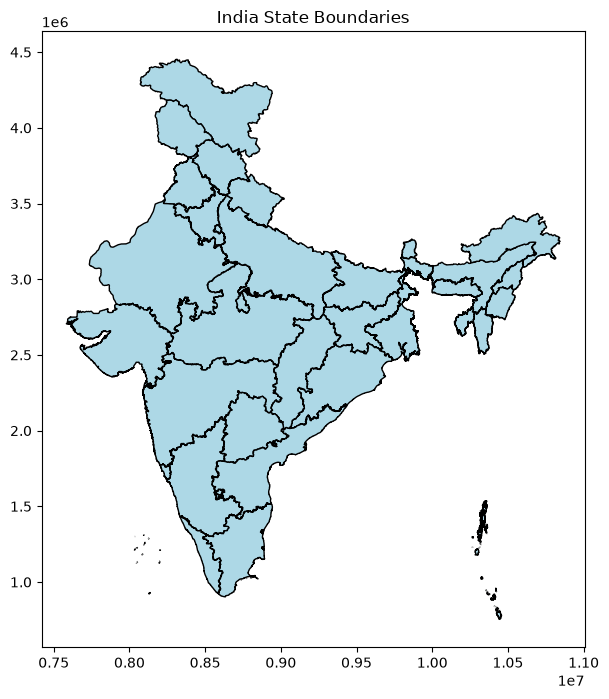

In [10]:
states.plot(
    figsize=(10, 8),
    color="lightblue",
    edgecolor="black"
)

plt.title("India State Boundaries")
plt.show()

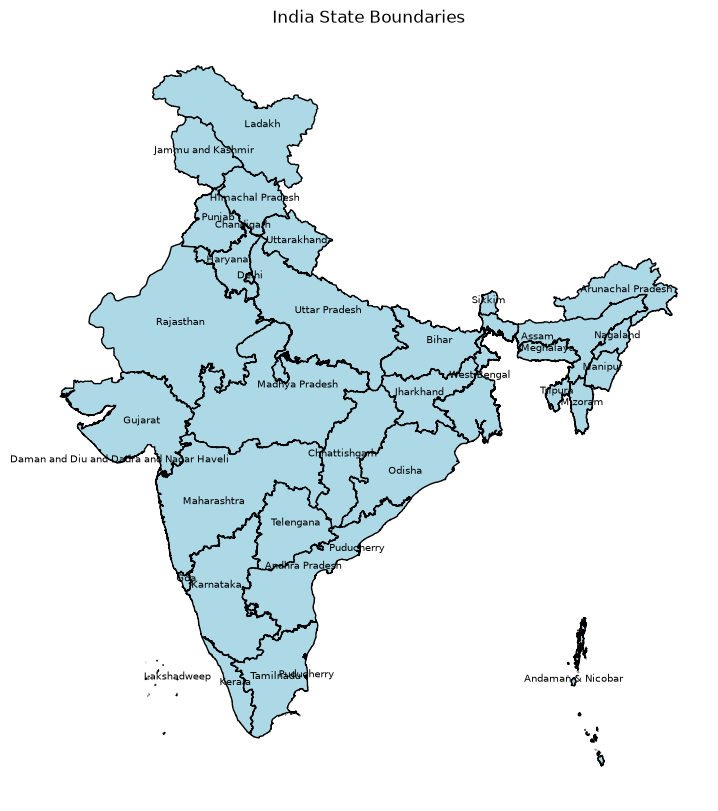

In [11]:
fig, ax = plt.subplots(figsize=(12, 10))

states.plot(
    ax=ax,
    color="lightblue",
    edgecolor="black"
)

for idx, row in states.iterrows():
    point = row.geometry.representative_point()

    ax.text(
        point.x,
        point.y,
        row["State_Name"],
        fontsize=7,
        ha="center"
    )

plt.title("India State Boundaries")
plt.axis("off")
plt.show()

In [12]:
states["State_Name"]

0                            Andaman & Nicobar
1                                   Chandigarh
2     Daman and Diu and Dadra and Nagar Haveli
3                                        Delhi
4                                      Haryana
5                                    Jharkhand
6                                    Karnataka
7                                       Kerala
8                                  Lakshadweep
9                               Madhya Pradesh
10                                 Maharashtra
11                                      Odisha
12                                  Puducherry
13                                   Tamilnadu
14                               Chhattishgarh
15                                   Telengana
16                              Andhra Pradesh
17                                  Puducherry
18                                         Goa
19                            Himachal Pradesh
20                                      Punjab
21           

In [13]:
odisha = states[
    states["State_Name"] == "Odisha"
]

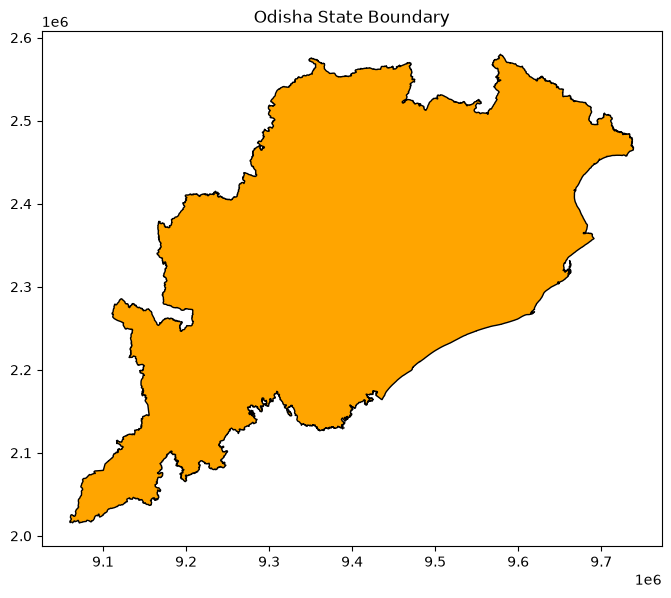

In [14]:
odisha.plot(
    figsize=(8, 8),
    color="orange",
    edgecolor="black"
)

plt.title("Odisha State Boundary")
plt.show()

In [15]:
selected = states[
    states["State_Name"].isin(
        ["Odisha", "West Bengal", "Jharkhand"]
    )
]

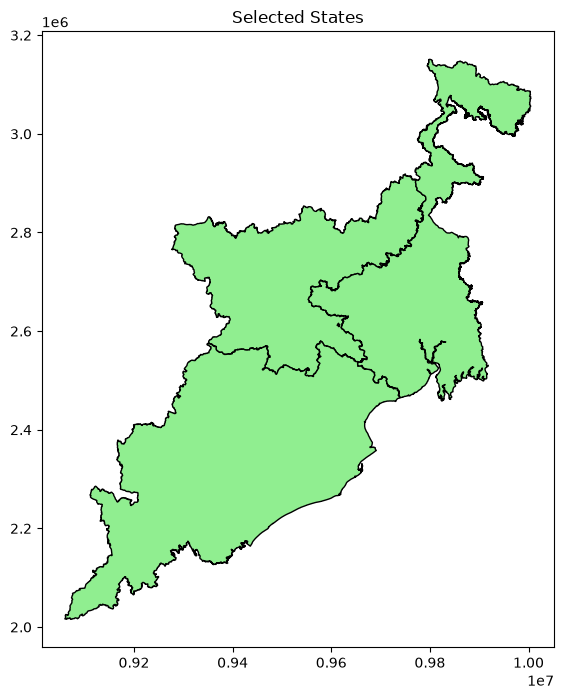

In [16]:
selected.plot(
    figsize=(8, 8),
    color="lightgreen",
    edgecolor="black"
)

plt.title("Selected States")
plt.show()

In [17]:
states_area = states.to_crs("EPSG:6933")

In [18]:
states_area["Area_m2"] = states_area.geometry.area

In [19]:
states_area.geometry.area

0     7.313767e+09
1     1.146091e+08
2     5.812267e+08
3     1.484868e+09
4     4.419171e+10
5     7.985953e+10
6     1.917999e+11
7     3.881221e+10
8     3.325219e+07
9     3.082227e+11
10    3.075044e+11
11    1.556454e+11
12    3.591421e+08
13    1.299867e+11
14    1.351594e+11
15    1.121346e+11
16    1.630524e+11
17    3.781316e+07
18    3.699697e+09
19    5.566215e+10
20    5.035605e+10
21    3.421752e+11
22    1.873541e+11
23    5.341698e+10
24    2.410118e+11
25    7.113442e+09
26    7.845616e+10
27    8.201784e+10
28    1.658987e+10
29    2.232219e+10
30    2.108209e+10
31    1.044812e+10
32    2.241610e+10
33    8.359100e+10
34    9.418503e+10
35    1.668754e+11
36    5.762339e+10
dtype: float64

In [20]:
states_area["Area_km2"] = (
    states_area["Area_m2"] / 1_000_000
)

In [21]:
states_area[
    ["State_Name", "Area_km2"]
].head()

,State_Name,Area_km2
0,Andaman & Nicobar,7313.766834
1,Chandigarh,114.609141
2,Daman and Diu and Dadra and Nagar Haveli,581.226715
3,Delhi,1484.867749
4,Haryana,44191.706719


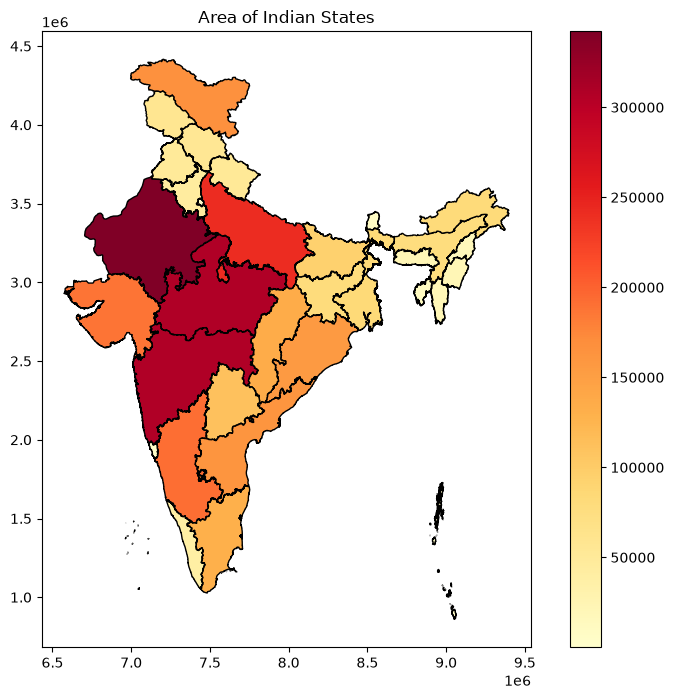

In [22]:
states_area.plot(
    column="Area_km2",
    cmap="YlOrRd",
    legend=True,
    figsize=(10, 8),
    edgecolor="black"
)

plt.title("Area of Indian States")
plt.show()

In [23]:
import pandas as pd

In [24]:
population = pd.read_csv(
    "India_State_Population_2011.csv"
)

In [25]:
population.head()

,State_Name,Population_2011
0,Andaman & Nicobar,380581
1,Chandigarh,1055450
2,Daman and Diu and Dadra and Nagar Haveli,586956
3,Delhi,16787941
4,Haryana,25351462


In [26]:
population.columns

Index(['State_Name', 'Population_2011'], dtype='str')

In [27]:
states_final = states_area.merge(
    population,
    on="State_Name",
    how="left"
)

In [28]:
on="State_Name"

In [29]:
how="left"

In [30]:
states_final.head()

,State_Name,geometry,Area_m2,Area_km2,Population_2011
0,Andaman & Nicobar,"MULTIPOLYGON (((8963694.856 1633522.88, 896372...",7.313767e+09,7313.766834,380581
1,Chandigarh,"POLYGON ((7407475.623 3746480.303, 7407527.441...",1.146091e+08,114.609141,1055450
2,Daman and Diu and Dadra and Nagar Haveli,"MULTIPOLYGON (((7039966.443 2541125.127, 70400...",5.812267e+08,581.226715,586956
3,Delhi,"POLYGON ((7439662.382 3532840.552, 7439736.612...",1.484868e+09,1484.867749,16787941
4,Haryana,"POLYGON ((7388461.64 3669938.345, 7388576.791 ...",4.419171e+10,44191.706719,25351462


In [31]:
states_final.columns

Index(['State_Name', 'geometry', 'Area_m2', 'Area_km2', 'Population_2011'], dtype='str')

In [32]:
states_final["Population_2011"].isna().sum()

np.int64(0)

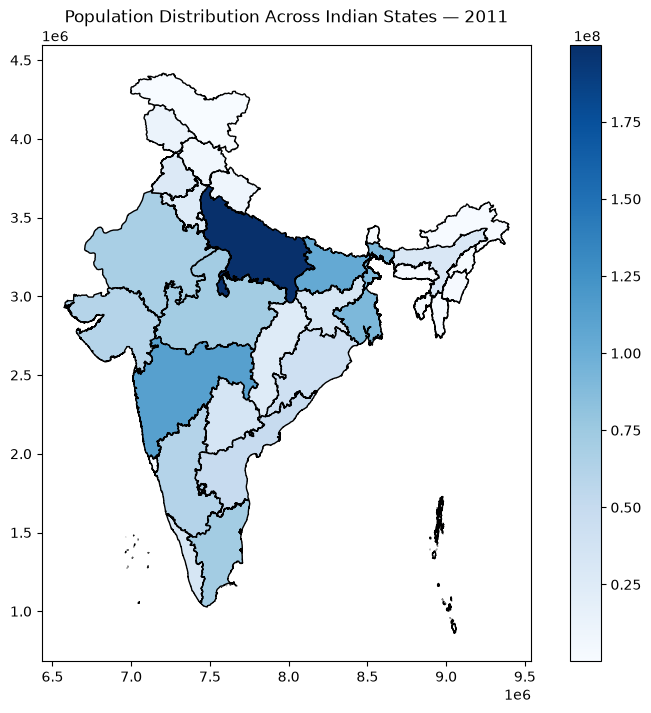

In [33]:
states_final.plot(
    column="Population_2011",
    cmap="Blues",
    legend=True,
    figsize=(10, 8),
    edgecolor="black"
)

plt.title("Population Distribution Across Indian States — 2011")
plt.show()

In [34]:
states_final["Population_Density"] = (
    states_final["Population_2011"]
    / states_final["Area_km2"]
)

In [35]:
states_final[
    [
        "State_Name",
        "Area_km2",
        "Population_2011",
        "Population_Density"
    ]
].head()

,State_Name,Area_km2,Population_2011,Population_Density
0,Andaman & Nicobar,7313.766834,380581,52.036250
1,Chandigarh,114.609141,1055450,9209.125863
2,Daman and Diu and Dadra and Nagar Haveli,581.226715,586956,1009.857230
3,Delhi,1484.867749,16787941,11306.017666
4,Haryana,44191.706719,25351462,573.670127


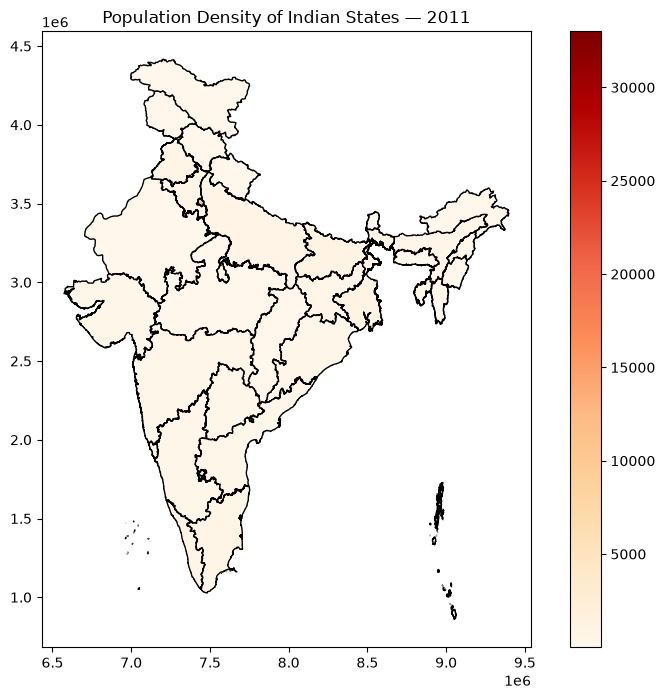

In [36]:
states_final.plot(
    column="Population_Density",
    cmap="OrRd",
    legend=True,
    figsize=(10, 8),
    edgecolor="black"
)

plt.title("Population Density of Indian States — 2011")
plt.show()

In [37]:
top_states = states_final.nlargest(
    10,
    "Population_2011"
)

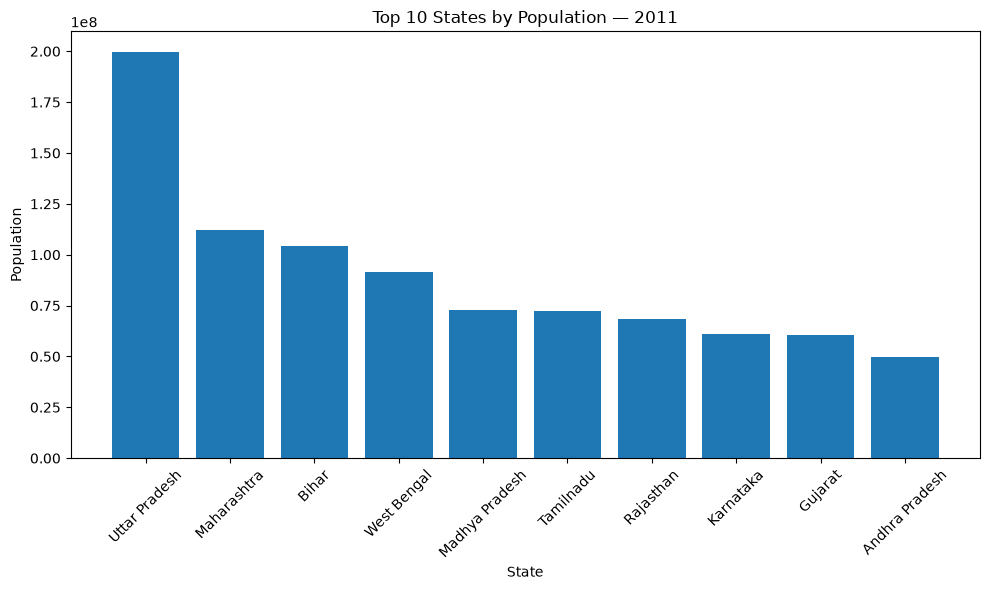

In [38]:
plt.figure(figsize=(10, 6))

plt.bar(
    top_states["State_Name"],
    top_states["Population_2011"]
)

plt.xticks(rotation=45)
plt.ylabel("Population")
plt.xlabel("State")
plt.title("Top 10 States by Population — 2011")

plt.tight_layout()
plt.show()